In [14]:
from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langchain_ollama import ChatOllama 
from typing import TypedDict,Literal
from dotenv import load_dotenv

In [2]:
generation_llm= ChatOllama(model="llama3.2:1b")
evaluator_llm= ChatOllama(model="qwen2.5:0.5b")
optimizer_llm= ChatOllama(model="smollm2:360m")

In [23]:
from pydantic import BaseModel, Field
class TweetEvaluation(BaseModel):
    evaluation: Literal["approved", "needs_improvement"] = Field(..., description="Final evaluation result.")
    feedback: str = Field(..., description="Constructive feedback for the tweet.")
    

In [24]:
structured_evaluator_llm=evaluator_llm.with_structured_output(TweetEvaluation)

In [25]:
# state
class TweekState(TypedDict):
    topic:str
    tweet:str
    evaluation:Literal["approaved","need_improvement"]

    feedback:str

    iteration:int

    # for close the workflow(loop)
    max_iteration:int


In [16]:
def generate_tweet(state:TweekState):
    # prompt->LLM for tweet 
    messages = [
    SystemMessage(content="You are a funny and clever Twitter/X influencer."),
    HumanMessage(content=f"""
Write a short, original, and hilarious tweet on the topic: "{state['topic']}".

Rules:
- Do NOT use question-answer format.
- Max 280 characters.
- Use observational humor, irony, sarcasm, or cultural references.
- Think in meme logic, punchlines, or relatable takes.
- Use simple, day to day english.
""")
]

    # send to the generator LLM
    response=generation_llm.invoke(messages).content

    # return response (tweet used store the response)
    return {'tweet':response}



In [17]:
def evaluate_tweet(state:TweekState):
    # evaluate prompt (send to generation tweet )
    messages = [
    SystemMessage(content="You are a ruthless, no-laugh-given Twitter critic. You evaluate tweets based on humor, originality, virality, and tweet format."),
    HumanMessage(content=f"""
Evaluate the following tweet:

Tweet: "{state['tweet']}"

Use the criteria below to evaluate the tweet:

1. Originality - Is this fresh, or have you seen it a hundred times before?
2. Humor - Did it genuinely make you smile, laugh, or chuckle?
3. Punchiness - Is it short, sharp, and scroll-stopping?
4. Virality Potential - Would people retweet or share it?
5. Format - Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?

Auto-reject if:
- It's written in question-answer format (e.g., "Why did..." or "What happens when...")
- It exceeds 280 characters
- It reads like a traditional setup-punchline joke
- It doesn't end with generic, throwaway, or deflating lines that weaken the humor (e.g., "Masterpieces of the auntie-uncle universe" or vague summaries)

### Respond ONLY in structured format:
- evaluation: "approved" or "needs_improvement"
- feedback: One paragraph explaining the strengths and weaknesses
""")
]

    response=structured_evaluator_llm.invoke(messages) 
    return{'evaluation':response.evaluation,'feedback':response.feedback}




In [18]:
def optimize_tweet(state:TweekState):
    messages = [
    SystemMessage(content="You punch up tweets for virality and humor based on given feedback."),
    HumanMessage(content=f"""
Improve the tweet based on this feedback:
"{state['feedback']}"

Topic: "{state['topic']}"
Original Tweet:
{state['tweet']}

Re-write it as a short, viral-worthy tweet. Avoid Q&A style and stay under 280 characters.
""")
]

    response=optimizer_llm.invoke(messages).content
    iteration=state['iteration']+1

    return {'tweet':response,'iteration':iteration}

In [19]:
# condition workflow 
def route_evaluation(state:TweekState):
    if state['evaluation']=='approaved' or state['iteration']>=state['max_iteration']:
        return 'approved'
    else:
        return 'needs_approvement'
    

In [28]:
graph=StateGraph(TweekState)

# nodes
graph.add_node('generate',generate_tweet)
graph.add_node('evaluate',evaluate_tweet)
graph.add_node('optimize',optimize_tweet)


# edges
graph.add_edge(START,'generate')
graph.add_edge('generate',"evaluate")

graph.add_conditional_edges('evaluate',route_evaluation,{'approved':END,'needs_approvement':'optimize'})

# loop edge 
graph.add_edge('optimize','evaluate')

workflow=graph.compile()


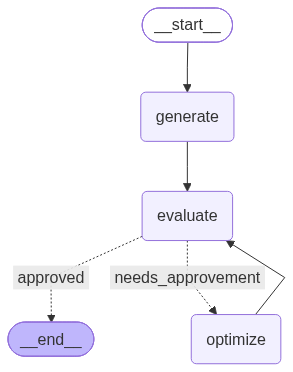

In [30]:
graph.compile()

In [29]:
initial_state={
    'topic':'indian Railway',
    'iteration':1,
    'max_iteration':5
}
workflow.invoke(initial_state)

{'topic': 'indian Railway',
 'tweet': '"Indian railways are family, so take the space you don\'t invite and invite the relatives who eat the snacks!" #IndianRailway #FamilyLife',
 'evaluation': 'needs_improvement',
 'feedback': "The tweet is not fresh or original. It has a repetitive phrase and lacks a punchy and engaging hook. It's best suited as a setup-punchline joke rather than a well-formed tweet. Instead, it should be used for a setup or a punchline that adds humor without making people question the authenticity of the content. For a more effective tweet, consider a more casual or traditional format, such as a direct quote or a joke that is built around a joke or a quote.",
 'iteration': 5,
 'max_iteration': 5}